# CVAE-GAN with normalised input frames and different loss weights $\tau$

**The problem: the CVAE-GAN learns the average frame.** The CVAE-GAN and its loss are taken from [14] (see
`pacman_vae.ipynb`). The loss fixes only $\tau_1 + \tau_2 + \tau_3 = 1$, so the weights have to be chosen for the data.
With equal weights, $\tau_1 = \tau_2 = \tau_3 = \tfrac13$, the trained encoder gives every latent slot
$\mu_{z,k} \approx 0$ and $\sigma_{z,k} \approx 1$, whatever frame it receives. The latent vector $z_k$ is then random
noise with no information about the frame, and the decoder can only redraw the average frame: its reconstruction
error is the same as always answering the mean frame.

**Why it happens.** Line 1 of the loss (the KL divergence) charges for every bit of information $z_k$ carries; line 2
rewards information only by the reconstruction error it removes. Lines 1 and 2 together are the loss of a standard
VAE that assumes Gaussian noise of variance $\sigma_x^2 = \tau_1/\tau_2$ on every tile. With equal weights that is noise
of about ±1, while the predicted crowd frames differ from their average by only a few hundredths per tile. To the loss,
these differences look like noise, and carrying no information at all is the cheapest solution. Equal weights
therefore cannot be used on these frames as they are.


**The test performed here.** Two changes are combined: the frames are **normalised**, so that a tile deviates from its
average by about 1 instead of a few hundredths, and the **loss weights are varied**, lowering $\tau_1$ (the weight of the KL
charge) step by step with $\tau_1 + \tau_2 + \tau_3 = 1$. Every setting is trained several times on several splits of the
viewers (section 1), and the weights are chosen on validation data and then scored on test data that the choice never
saw. Section 6 also decides between original and normalised frames with the same rule, and section 7 trains the final
model on all 50 viewers. The result is one table with four columns: $\tau_1$, $\tau_2$, $\tau_3$ and the RMSE.

## 0. Code

All the code used by this notebook is in the cells of this section; the experiment itself starts in section 1.

### Settings and paths

Every result is saved in `results/`; when the notebook is run again it loads the saved results instead of training
again, unless `RERUN = True`.

In [1]:
import os, time, random
from types import SimpleNamespace
from joblib import Parallel, delayed     # parallel runs that work on Linux, macOS and Windows

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# Paths are relative to this notebook's folder (run it with vae/pacman/ as the working directory):
#   ../../dataset/360dataset/sensory/tile/          input:  one tile CSV per viewer
#   ../../predictor/pacman/predictor_weights_pacman.pt input:  the settings of the trained FoV predictor
#   ./figures/, ./results/                       output: figures and results tables
DATA_ROOT      = os.path.join("..", "..", "dataset", "360dataset")
PREDICTOR_FILE = os.path.join("..", "..", "predictor", "pacman", "predictor_weights_pacman.pt")
FIG_DIR, RES_DIR = "figures", "results"
assert os.path.exists(PREDICTOR_FILE), f"{PREDICTOR_FILE} not found; run ../../predictor/pacman/fov_predictor_pacman.ipynb first"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

DEVICE = torch.device("cpu")
torch.set_num_threads(1)
N_WORKERS = max(1, min(6, (os.cpu_count() or 2) - 1))
RERUN = False                            # False: load saved results if they exist; True: train every run again

BLUE, ORANGE, GREEN, GREY = "#1f5fbf", "#d9480f", "#2b8a3e", "#7a7a7a"
pd.set_option("display.width", 200)

### Data and viewer folds

Each viewer's tile CSV becomes 12 FoV maps, one every 5 s (10 × 20 tiles, 1 = tile in view). The 50 viewers are split
into 5 folds of 10: viewer number $i$ goes to fold $i \bmod 5$. `split(f)` gives the roles of the folds in turn $f$
(section 1).

In [2]:
ck  = torch.load(PREDICTOR_FILE, map_location=DEVICE)
cfg = ck["cfg"]                                                # the predictor's settings (video, grid, order n, ...)
H, W, N = cfg["H"], cfg["W"], cfg["n"]
N_SAMPLES   = cfg["video_seconds"] // cfg["sample_every_s"]    # 12 FoV maps per viewer, one every 5 s
KS          = list(range(N + 1, N_SAMPLES + 1))                # the 7 predicted time steps k = 6..12
CROWD       = cfg["users_per_epoch"]                           # 10 viewers per crowd
PRED_EPOCHS = -(-int(cfg["video_hours"] * 3600) // (CROWD * (N_SAMPLES - N) * cfg["sample_every_s"]))   # 494
VAE_EPOCHS  = 2 * PRED_EPOCHS                                  # 988
U = ck["U"]                                                    # the 50 viewers


def parse_tile_csv(path):
    # ragged 'frame, tile, tile, ...' CSV  ->  (n_frames, H, W) array of 0/1
    occ = []
    with open(path) as f:
        f.readline()
        for line in f:
            parts = [p.strip() for p in line.strip().split(",")]
            if not parts or parts[0] == "":
                continue
            g = np.zeros((H, W), np.float32)
            for x in (int(p) for p in parts[1:] if p != ""):
                j, i = divmod(x, W)
                if 0 <= j < H and 0 <= i < W:
                    g[j, i] = 1.0
            occ.append(g)
    return np.stack(occ)


step = cfg["sample_every_s"] * cfg["fps"]
G = {}                                                         # G[u]: the 12 FoV maps of viewer u, (12, H, W)
for u in U:
    occ = parse_tile_csv(os.path.join(DATA_ROOT, "sensory", "tile", cfg['folder'], f"{cfg['prefix']}_{u}_tile.csv"))
    G[u] = occ[[min(k * step, len(occ)) - 1 for k in range(1, N_SAMPLES + 1)]]

# the 5 viewer folds: viewer number i goes to fold (i - 1) mod 5, so every fold holds 10 viewers spread over the list
FOLDS = [[u for i, u in enumerate(U) if i % 5 == f] for f in range(5)]


def split(f):
    # outer fold f: test = fold f; validation = fold f+1; inner training = the other 3 folds (30 viewers);
    # outer training = everything except the test fold (40 viewers)
    test, val = FOLDS[f], FOLDS[(f + 1) % 5]
    inner = [u for g in range(5) if g not in (f, (f + 1) % 5) for u in FOLDS[g]]
    outer = [u for g in range(5) if g != f for u in FOLDS[g]]
    return SimpleNamespace(test=test, val=val, inner_train=inner, outer_train=outer)

### The FoV predictor, trained per fold

`train_predictor(users)` trains the FoV predictor network of `../../predictor/pacman/fov_predictor_pacman.ipynb` on the given
viewers only. It uses the predictor's first training procedure: 494 plain gradient-descent steps on the squared
error, each on a random group of 10 viewers. The saved predictor of that notebook was later retrained with Adam on
binary cross-entropy (`../../predictor/fov_videos_summary.md`); the fold predictors here keep the first procedure.
Only the final model (section 7 of `pacman_vae_normalised_and_diff_weights.ipynb`) uses the saved predictor. `crowd_frames` averages the FoV maps of a group of viewers into crowd frames
and turns each window of 5 into a predicted frame $\hat F_k$, $k = 6, \dots, 12$: the input $X$ of the CVAE-GAN.
`training_frames` draws a new random group of 10 training viewers for each of the 988 epochs.

In [3]:
class CircularPad(nn.Module):
    # wrap columns (longitude, the 360-degree seam), zero-pad rows (latitude). x is (batch, C, H, W)
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        p = self.p
        x = torch.cat([x[..., -p:], x, x[..., :p]], dim=3)
        return nn.functional.pad(x, (0, 0, p, p))


class Order5Predictor(nn.Module):
    def __init__(self, base_rate, n=5, width=16):
        super().__init__()
        self.pad1, self.conv1 = CircularPad(1), nn.Conv2d(n, width, 3)
        self.pad2, self.conv2 = CircularPad(2), nn.Conv2d(width, width, 3, dilation=2)
        self.head = nn.Conv2d(width, 1, 1)
        for conv in (self.conv1, self.conv2, self.head):
            nn.init.xavier_uniform_(conv.weight); nn.init.zeros_(conv.bias)
        nn.init.constant_(self.head.bias, float(np.log(base_rate / (1 - base_rate))))

    def forward(self, x):                                       # x: (batch, H, W, n), oldest map first
        h = x.permute(0, 3, 1, 2)
        h = torch.relu(self.conv1(self.pad1(h)))
        h = torch.relu(self.conv2(self.pad2(h)))
        return torch.sigmoid(self.head(h)).squeeze(1)          # (batch, H, W)


def train_predictor(users):
    """The FoV predictor of ../../predictor/pacman/fov_predictor_pacman.ipynb, trained on `users` only, with its first procedure (494 plain gradient-descent steps)."""
    torch.set_num_threads(1)
    X = np.stack([np.stack([np.moveaxis(G[u][k - 1 - N:k - 1], 0, -1) for k in KS]) for u in users]).astype(np.float32)
    Y = np.stack([np.stack([G[u][k - 1] for k in KS]) for u in users]).astype(np.float32)
    X_t, Y_t = torch.from_numpy(X), torch.from_numpy(Y)        # (users, 7, H, W, n) and (users, 7, H, W)
    random.seed(cfg["seed"]); np.random.seed(cfg["seed"]); torch.manual_seed(cfg["seed"])
    model = Order5Predictor(float(Y.mean()), N, cfg["width"])
    rng, used, groups = np.random.default_rng(cfg["seed"]), set(), []
    while len(groups) < PRED_EPOCHS:                           # one distinct group of 10 viewers per epoch
        s = tuple(sorted(rng.choice(len(users), CROWD, replace=False).tolist()))
        if s not in used:
            used.add(s); groups.append(s)
    for e, s in enumerate(groups, start=1):
        idx = torch.tensor(s)
        Xb, Yb = X_t[idx].reshape(-1, H, W, N), Y_t[idx].reshape(-1, H, W)
        loss = torch.mean(torch.sum(torch.square(model(Xb) - Yb), dim=(1, 2)))
        grads = torch.autograd.grad(loss, list(model.parameters()))
        with torch.no_grad():
            for v, g in zip(model.parameters(), grads):
                v.sub_(cfg["lr_a"] / (cfg["lr_b"] + e) * g)     # plain gradient descent, eta_e = a / (b + e)
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


@torch.no_grad()
def crowd_frames(predictor, groups):
    """For each group of viewers: average their FoV maps into crowd frames F_k, then predict F_hat_6..F_hat_12."""
    X = []
    for users in groups:
        F = np.mean([G[u] for u in users], axis=0)                                     # (12, H, W)
        X.append(np.stack([np.moveaxis(F[k - 1 - N:k - 1], 0, -1) for k in KS]))       # (7, H, W, n)
    X = torch.from_numpy(np.concatenate(X).astype(np.float32))
    return predictor(X).numpy().reshape(len(groups), len(KS), H, W)


def training_frames(predictor, users, rng):
    """988 epochs: each one a random group of 10 of `users` -> its 7 predicted frames. Shape (988, 7, H, W)."""
    groups = [list(rng.choice(users, CROWD, replace=False)) for _ in range(VAE_EPOCHS)]
    return crowd_frames(predictor, groups)

### Normalisation

`make_normaliser(frames)` computes $\bar X$ and $s$ on the training frames of a run and returns the transform
$X' = (X - \bar X)/s$ and its inverse (explained in section 2).

In [4]:
def make_normaliser(frames):
    """X' = (X - X_bar) / s with X_bar the mean training frame and s the RMSE of always answering X_bar."""
    mean = frames.reshape(-1, H, W).mean(0)
    s = float(np.sqrt(np.mean((frames - mean) ** 2)))
    return SimpleNamespace(mean=mean, scale=s,
                           fwd=lambda A: ((A - mean) / s).astype(np.float32),
                           inv=lambda A: (A * s + mean).astype(np.float32))

### The CVAE-GAN

The same model, loss and training as `pacman_vae.ipynb`:

- **encoder** 200 → 128 → 64 → ($\mu_{z,k}$, $\log\sigma^2_{z,k}$), 10 latent slots; **decoder** 10 → 64 → 128 → 200;
  **discriminator** 200 → 128 → 64 → 1; LeakyReLU 0.2 in the hidden layers;
- $z_k = \mu_{z,k} + \sigma_{z,k}\,\varepsilon$, $\varepsilon \sim \mathcal N(0, 1)$;
- **the latent vector is squashed into (0, 1)** before it is decoded: the decoder receives
  $\mathrm{sigmoid}(z_k) = 1/(1 + e^{-z_k})$, so every one of the 10 numbers lies between 0 and 1, and the reconstruction
  error measures what survives this squashing. Line 1 (KL) is computed on $z_k$ before the sigmoid;
- loss $\mathcal L = \tau_1\,\text{line 1 (KL)} + \tau_2\,\text{line 2 (reconstruction)} + \tau_3\,\text{line 3 (discriminator)}$;
- one epoch = one group's 7 frames = one discriminator step, then one encoder + decoder step; Adam, learning rate
  0.001, 988 epochs.

On normalised frames the decoder output is linear (no sigmoid) and its bias starts at 0; on original frames it ends in
a sigmoid whose bias starts at the average tile value. `evaluate` returns the reconstruction RMSE on the original
0–1 tile scale (decoding $\mu_{z,k}$), the number of **active** latent slots (mean $\sigma_{z,k} < 0.5$; a collapsed slot has
$\sigma_{z,k} \approx 1$) and the KL in nats.

In [5]:
def mlp(sizes, leak):
    return [m for a, b in zip(sizes, sizes[1:]) for m in (nn.Linear(a, b), nn.LeakyReLU(leak))]


class Encoder(nn.Module):
    # X  ->  (mu_{z,k}, log sigma_{z,k}^2)
    def __init__(self, L=10, hidden=(128, 64), leak=0.2):
        super().__init__()
        sizes = [H * W, *hidden]
        self.body, self.to_mu, self.to_lv = nn.Sequential(*mlp(sizes, leak)), nn.Linear(sizes[-1], L), nn.Linear(sizes[-1], L)

    def forward(self, X):
        h = self.body(X.flatten(1))
        return self.to_mu(h), self.to_lv(h)


class Decoder(nn.Module):
    # sigmoid(z_k) -> X_recon. Sigmoid output for frames in [0, 1]; linear output for normalised frames.
    def __init__(self, L=10, hidden=(128, 64), leak=0.2, out_sigmoid=True, out_bias=0.0):
        super().__init__()
        sizes = [L, *hidden[::-1]]
        self.out_sigmoid = out_sigmoid
        self.net = nn.Sequential(*mlp(sizes, leak), nn.Linear(sizes[-1], H * W))
        nn.init.constant_(self.net[-1].bias, out_bias)

    def forward(self, z):
        y = self.net(torch.sigmoid(z))          # the latent vector z_k is squashed into (0, 1) before it is decoded
        return (torch.sigmoid(y) if self.out_sigmoid else y).view(-1, H, W)


class Discriminator(nn.Module):
    # D(X) in (0, 1): probability that a frame is a real predicted frame
    def __init__(self, d_hidden=(128, 64), leak=0.2):
        super().__init__()
        sizes = [H * W, *d_hidden]
        self.net = nn.Sequential(*mlp(sizes, leak), nn.Linear(sizes[-1], 1))

    def logit(self, X):
        return self.net(X.flatten(1)).squeeze(1)

    def forward(self, X):
        return torch.sigmoid(self.logit(X))


def draw_z(mu, lv):
    # z_k = mu + sigma * eps,  eps ~ N(0, 1)
    return mu + torch.exp(0.5 * lv) * torch.empty_like(mu).normal_()


def loss_enc(mu, lv):            # line 1: KL to N(0, 1), summed over the slots, mean over the batch
    return torch.mean(-0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp(), dim=1))

def loss_dec(X, X_recon):        # line 2: 1/2 ||X - X_recon||^2 summed over the tiles, mean over the batch
    return torch.mean(0.5 * torch.sum(torch.square(X - X_recon), dim=(1, 2)))

def loss_disc(disc, X, X_recon): # line 3: E[log D(X)] + E[log(1 - D(X_recon))]
    return (torch.mean(nn.functional.logsigmoid(disc.logit(X)))
            + torch.mean(nn.functional.logsigmoid(-disc.logit(X_recon))))


def train_cvaegan(train, tau, out_sigmoid, out_bias, lr=1e-3, decay=1e-6):
    """One epoch = one group's 7 frames = one discriminator step, then one encoder + decoder step."""
    enc, dec, disc = Encoder(), Decoder(out_sigmoid=out_sigmoid, out_bias=out_bias), Discriminator()
    opt_ed = torch.optim.Adam([*enc.parameters(), *dec.parameters()], lr=lr)
    opt_d  = torch.optim.Adam(disc.parameters(), lr=lr)
    scheds = [torch.optim.lr_scheduler.LambdaLR(o, lambda t: 1.0 / (1.0 + decay * t)) for o in (opt_ed, opt_d)]
    for X_np in train:
        X = torch.from_numpy(X_np)
        with torch.no_grad():                                   # (1) discriminator: maximise line 3
            mu, lv = enc(X)
            X_fake = dec(draw_z(mu, lv))
        L_D = -tau[2] * loss_disc(disc, X, X_fake)
        opt_d.zero_grad(); L_D.backward(); opt_d.step()
        mu, lv = enc(X)                                         # (2) encoder + decoder: minimise L
        X_recon = dec(draw_z(mu, lv))
        L = tau[0] * loss_enc(mu, lv) + tau[1] * loss_dec(X, X_recon) + tau[2] * loss_disc(disc, X, X_recon)
        opt_ed.zero_grad(); L.backward(); opt_ed.step()
        for sch in scheds:
            sch.step()
    enc.eval(); dec.eval(); disc.eval()
    return enc, dec


@torch.no_grad()
def evaluate(enc, dec, A, scale=1.0):
    """Reconstruction RMSE on the original tile scale (decoding mu), active slots and KL on the frames A."""
    A_t = torch.from_numpy(A)
    mu, lv = enc(A_t)
    sig = torch.exp(0.5 * lv).mean(0)
    return {"rmse": float(torch.sqrt(torch.mean(torch.square(dec(mu) - A_t)))) * scale,
            "active": int((sig < 0.5).sum()), "kl": float(loss_enc(mu, lv))}


def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

### Running many trainings

`run_one(task)` trains one CVAE-GAN for one turn, stage (`"val"` or `"test"`), setting and repeat, and scores it on the
7 frames of the validation or test fold. It also records the error of always answering the mean training frame on
the same frames. `run_all(tasks, csv)` runs a list of tasks in parallel and saves one row per run.

In [6]:
# The fold predictors: for outer fold f, one predictor trained on the 30 inner-training viewers (used to choose the
# setting on the validation fold) and one trained on the 40 outer-training viewers (used for the test fold).
def fold_predictors():
    t0, P = time.time(), {}
    for f in range(5):
        sp = split(f)
        P[(f, "val")]  = train_predictor(sp.inner_train)
        P[(f, "test")] = train_predictor(sp.outer_train)
    print("10 fold predictors trained")
    return P


def run_one(task):
    """Train one CVAE-GAN and score it. task = (fold, stage, tau, normalised, repeat); stage is 'val' or 'test'.

    No random seed is fixed: every run starts from fresh random numbers. The seed it happened to use is recorded so
    that any single run can be repeated exactly.
    """
    f, stage, tau, normalised, rep = task
    torch.set_num_threads(1)
    seed = int.from_bytes(os.urandom(4), "little")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    sp, pred = split(f), PREDICTORS[(f, stage)]
    train = training_frames(pred, sp.inner_train if stage == "val" else sp.outer_train, np.random.default_rng(seed))
    A = crowd_frames(pred, [sp.val if stage == "val" else sp.test])[0]          # the 7 frames that are scored
    mean_frame = train.reshape(-1, H, W).mean(0)
    if normalised:
        nm = make_normaliser(train)
        enc, dec = train_cvaegan(nm.fwd(train), tau, out_sigmoid=False, out_bias=0.0)
        ev = evaluate(enc, dec, nm.fwd(A), nm.scale)
    else:
        m = float(train.mean())
        enc, dec = train_cvaegan(train, tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
        ev = evaluate(enc, dec, A)
    return {"fold": f + 1, "stage": stage, "tau_1": tau[0], "tau_2": tau[1], "tau_3": tau[2],
            "normalised": normalised, "repeat": rep + 1, "seed": seed, **ev,
            "mean_frame_rmse": rmse(np.broadcast_to(mean_frame, A.shape), A)}


def run_all(tasks, csv_name):
    """Run every task in parallel (or load the saved results), and save them to results/csv_name."""
    path = os.path.join(RES_DIR, csv_name)
    if os.path.exists(path) and not RERUN:
        print(f"loaded {len(pd.read_csv(path))} saved runs from {path}  (set RERUN = True to train them again)")
        return pd.read_csv(path)
    t0 = time.time()
    rows = Parallel(n_jobs=N_WORKERS)(delayed(run_one)(t) for t in tasks)
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    print(f"{len(df)} runs saved to {path}")
    return df

### Helper functions for tables and figures

Functions that average the runs of each setting, pick the setting with the lowest validation RMSE in each turn, and draw
the figures.

In [7]:
def fmt(t):
    return "1/3" if abs(t - 1 / 3) < 1e-9 else (f"{t:.0e}".replace("e-0", "e-") if t < 0.01 else f"{t:.4g}")


def summarise(df, by=("tau_1", "tau_2", "tau_3")):
    # one row per setting: mean and standard deviation of the RMSE over all its runs, mean active slots and KL
    g = df.groupby(list(by))
    out = g.agg(rmse_mean=("rmse", "mean"), rmse_std=("rmse", "std"), active=("active", "mean"),
                kl=("kl", "mean"), mean_frame=("mean_frame_rmse", "mean"), runs=("rmse", "size")).reset_index()
    if "tau_1" in by:
        out["ratio"] = out.tau_1 / out.tau_2
    return out


def choose_per_fold(val, by=("tau_1", "tau_2", "tau_3")):
    # in each turn: the setting with the lowest validation RMSE averaged over its repeats
    m = val.groupby(["fold", *by]).rmse.mean().reset_index()
    return m.loc[m.groupby("fold").rmse.idxmin()].reset_index(drop=True)


def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"


def eigenvalues(frames):
    # variance of the frames along each principal direction, largest first (sums to the total variance)
    A = frames.reshape(-1, H * W).astype(np.float64)
    s = np.linalg.svd(A - A.mean(0), compute_uv=False)
    return s ** 2 / len(A)


def plot_eigenvalues(lam, ratios, title, path):
    fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
    ax.semilogy(np.arange(1, 31), lam[:30], "o-", color=BLUE, ms=4, label="variance of the frames along direction $i$")
    for r, ls in zip(ratios, ["-", "--", "-.", ":"]):
        ax.axhline(r, color=ORANGE, ls=ls, lw=1.2, label=f"$\\tau_1/\\tau_2$ = {r:g}: {int((lam > r).sum())} directions above")
    ax.axvline(10.5, color=GREY, lw=0.8)
    ax.text(10.7, lam[:30].min(), "10 latent slots", color=GREY, fontsize=8, va="bottom")
    ax.set_xlabel("principal direction $i$"); ax.set_ylabel("variance (log scale)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(path, dpi=150)
    plt.show()


def plot_validation(summary, title, path):
    # mean +- standard deviation of the validation RMSE against tau_1/tau_2, one line per tau_3; right: active slots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
    for t3, color, ls, mk in zip(sorted(summary.tau_3.unique(), reverse=True), [BLUE, ORANGE, GREEN], ["-", "--", "-."], ["o", "s", "^"]):
        s = summary[np.isclose(summary.tau_3, t3)].sort_values("ratio")
        ax1.errorbar(s.ratio, s.rmse_mean, yerr=s.rmse_std, ls=ls, marker=mk, color=color, capsize=3, label=f"$\\tau_3$ = {fmt(t3)}")
        ax2.plot(s.ratio, s.active, ls=ls, marker=mk, color=color, label=f"$\\tau_3$ = {fmt(t3)}")
    ax1.axhline(summary.mean_frame.mean(), color=GREY, ls=":", lw=1.2, label="mean frame (no latent)")
    ax1.set_ylabel("validation RMSE (mean ± std of 25 runs)"); ax1.set_title("Reconstruction error", fontsize=10)
    ax2.set_ylim(-0.5, 10.5); ax2.set_ylabel("active slots (of 10, mean of 25 runs)"); ax2.set_title("Latent slots in use", fontsize=10)
    for a in (ax1, ax2):
        a.set_xscale("log"); a.set_xlabel("$\\tau_1 / \\tau_2$ (log scale)")
        a.legend(fontsize=8, frameon=False); a.grid(alpha=0.25); a.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=11)
    fig.savefig(path, dpi=150)
    plt.show()


@torch.no_grad()
def example_run(f, tau, normalised):
    # one extra run of a setting in turn f (trained on the 40 non-test viewers), for the figures: the 7 test frames,
    # their reconstruction from one drawn z_k, and the mean sigma of each latent slot
    sp, pred = split(f), PREDICTORS[(f, "test")]
    train = training_frames(pred, sp.outer_train, np.random.default_rng())
    A = crowd_frames(pred, [sp.test])[0]
    with torch.enable_grad():
        if normalised:
            nm = make_normaliser(train)
            enc, dec = train_cvaegan(nm.fwd(train), tau, out_sigmoid=False, out_bias=0.0)
        else:
            m = float(train.mean())
            enc, dec = train_cvaegan(train, tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
    X = torch.from_numpy(nm.fwd(A) if normalised else A)
    mu, lv = enc(X)
    R = dec(draw_z(mu, lv)).numpy()
    return A, (nm.inv(R) if normalised else R), torch.exp(0.5 * lv).mean(0).numpy()


def plot_reconstruction(A, R, title, path):
    vm, err = float(max(A.max(), R.max())), np.abs(R - A)
    fig, axes = plt.subplots(3, len(KS), figsize=(2.4 * len(KS), 5.0), constrained_layout=True)
    for col, k in enumerate(KS):
        im0 = axes[0, col].imshow(A[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
        axes[0, col].set_title(f"input $\\hat F_{{{k}}}$", fontsize=9)
        axes[1, col].imshow(R[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
        axes[1, col].set_title(f"redrawn, RMSE {rmse(R[col], A[col]):.4f}", fontsize=8)
        im2 = axes[2, col].imshow(err[col], cmap="Oranges", vmin=0, vmax=float(err.max()), interpolation="nearest")
        axes[2, col].set_title("|redrawn - input|", fontsize=8)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im0, ax=axes[:2], shrink=0.8, label="share of the crowd")
    fig.colorbar(im2, ax=axes[2], shrink=0.9, label="error")
    fig.suptitle(title, fontsize=11)
    fig.savefig(path, dpi=150)
    plt.show()


def plot_slots(sigma, title, path):
    dims = np.arange(1, len(sigma) + 1)
    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.bar(dims, sigma, color=[BLUE if s < 0.5 else "#bbbbbb" for s in sigma])
    ax.axhline(1.0, color=GREY, ls=":", lw=1.2, label="standard normal, sigma = 1 (collapsed)")
    ax.axhline(0.5, color=GREY, ls="--", lw=1, label="active threshold 0.5")
    ax.set_xticks(dims); ax.set_xlabel("latent slot"); ax.set_ylabel("mean sigma_z (test fold)")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=8, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(path, dpi=150)
    plt.show()

## 1. How the settings are compared

Every setting is trained and scored in exactly the same way, and the choice of the best setting never sees the data
it is finally scored on. This is standard nested cross-validation with the viewers as groups; it is not a new
method, and is used only so that no setting is chosen on the viewers it is scored on.

- **Viewer folds.** The 50 viewers are split into 5 folds of 10 (viewer number $i$ goes to fold $i \bmod 5$). Each fold
  takes one turn as the **test fold**, so every viewer is tested exactly once.
- **Validation inside the training viewers.** In each turn, the next fold is the **validation fold** and the other
  30 viewers are the **training viewers**. Settings are compared on the validation fold only. The chosen setting is
  then trained on all 40 non-test viewers and scored once on the test fold.
- **A predictor for every turn.** The FoV predictor is retrained in every turn on the training viewers only (30 for
  validation, 40 for the test), with the first training procedure of `../../predictor/pacman/fov_predictor_pacman.ipynb` (section 0). The frames of validation
  and test viewers therefore come from a predictor that has never seen those viewers.
- **Repeats.** Every setting is trained 5 times in every turn, each time from fresh random starting weights and fresh
  random groups of viewers. No random seed is fixed; the seed each run happened to use is saved with its result.
- **The rule, fixed before any run.** In each turn, the setting with the lowest validation RMSE averaged over its 5
  repeats is chosen. Its test RMSE, over the 5 turns × 5 repeats, is the reported result. The final setting is the one
  with the lowest validation RMSE averaged over all 25 runs.

A fold has 10 viewers, which form one crowd and therefore 7 predicted frames ($k = 6, \dots, 12$). All RMSE values are
reconstruction errors on the original 0–1 tile scale.


### The weights tried

The grid is fixed before any training. $\tau_1$ (the weight of the KL charge) goes from $\tfrac13$ (equal weights) down
five orders of magnitude, so the assumed noise $\sigma_x = \sqrt{\tau_1/\tau_2}$ goes from about 1 to about 0.004, well
past the size of the real differences between frames. $\tau_3$ (the discriminator's weight) takes three values, and
$\tau_2$ is whatever is left so that the weights add up to 1:

$$\tau_1 \in \{\tfrac13,\ 10^{-1},\ 10^{-2},\ 10^{-3},\ 10^{-4},\ 10^{-5}\},\qquad
\tau_3 \in \{\tfrac13,\ 0.1,\ 0.01\},\qquad \tau_2 = 1 - \tau_1 - \tau_3.$$

That is 18 settings, each trained 5 times in each of the 5 turns: 450 runs on the validation folds.

In [8]:
fold_table = pd.DataFrame([{"turn": f + 1, "test fold": f + 1, "validation fold": (f + 1) % 5 + 1,
                            "test viewers": ", ".join(u.replace("user", "") for u in split(f).test)} for f in range(5)])
print(fold_table.to_string(index=False))

# the 10 fold predictors (two per turn), trained in parallel
jobs = [(f, stage) for f in range(5) for stage in ("val", "test")]
t0 = time.time()
trained = Parallel(n_jobs=N_WORKERS)(delayed(train_predictor)(split(f).inner_train if s == "val" else split(f).outer_train)
                                     for f, s in jobs)
PREDICTORS = dict(zip(jobs, trained))
print(f"\n10 fold predictors trained "
      f"(turn f: one on its 30 training viewers for validation, one on its 40 non-test viewers for the test)")

 turn  test fold  validation fold                           test viewers
    1          1                2 01, 06, 11, 16, 21, 26, 31, 36, 41, 46
    2          2                3 02, 07, 12, 17, 22, 27, 32, 37, 42, 47
    3          3                4 03, 08, 13, 18, 23, 28, 33, 38, 43, 48
    4          4                5 04, 09, 14, 19, 24, 29, 34, 39, 44, 49
    5          5                1 05, 10, 15, 20, 25, 30, 35, 40, 45, 50



10 fold predictors trained (turn f: one on its 30 training viewers for validation, one on its 40 non-test viewers for the test)


## 2. How the frames are normalised

$$X' = \frac{X - \bar X}{s}, \qquad \bar X = \text{the mean training frame}, \qquad
s = \sqrt{\tfrac{1}{N\,D}\textstyle\sum_n \lVert X_n - \bar X\rVert^2} = \text{the RMSE of always answering } \bar X.$$

After this, a tile deviates from its average by about 1 instead of a few hundredths. $\bar X$ and $s$ are computed in every
run from that run's training frames only and then applied to the frames it is scored on.

- **One scale for all tiles, not one per tile.** Tiles far from the action hardly ever change; dividing each of
  them by its own tiny spread would blow tiny fluctuations up to the same size as the real movement of the crowd.
  One $s$ keeps the shape of the frames and only changes their scale.
- **The decoder's output is linear**, without the sigmoid: normalised tiles are no longer between 0 and 1 and can be
  negative. Its output bias starts at 0, the mean of $X'$.
- **The discriminator** sees normalised real and redrawn frames.
- **The RMSE is converted back** to the original tile scale, $\mathrm{RMSE} = s \cdot \mathrm{RMSE}'$ (the offset
  $\bar X$ cancels), so the numbers compare directly with models trained on the original frames.

**Why this has the same effect as changing the weights.** Dividing the frames by $s$ divides the variance along every
principal direction by $s^2$, so the rule "a slot is used if $\lambda_i/s^2 > \tau_1/\tau_2$" is the rule
"$\lambda_i > s^2 \cdot \tau_1/\tau_2$" on the original frames. With equal weights, normalising acts like
$\tau_1/\tau_2 = s^2$ ($s$ is printed below).

The figures show one test frame of turn 1 before and after normalising.

s = 0.0322


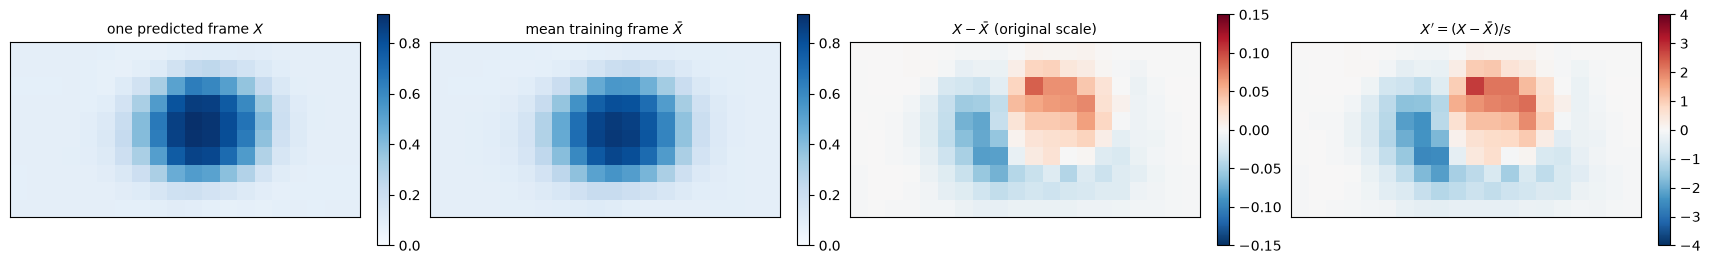

In [9]:
sp, pred = split(0), PREDICTORS[(0, "test")]
NORM = make_normaliser(training_frames(pred, sp.outer_train, np.random.default_rng()))   # one set of training frames
X0 = crowd_frames(pred, [sp.test])[0][-1]                                                 # the last test frame of turn 1
print(f"s = {NORM.scale:.4f}")
panels = [(X0, "one predicted frame $X$", "Blues", 0, float(X0.max())),
          (NORM.mean, "mean training frame $\\bar X$", "Blues", 0, float(X0.max())),
          (X0 - NORM.mean, "$X - \\bar X$ (original scale)", "RdBu_r", -0.15, 0.15),
          (NORM.fwd(X0), "$X' = (X - \\bar X)/s$", "RdBu_r", -4, 4)]
fig, axes = plt.subplots(1, 4, figsize=(17, 2.8), constrained_layout=True)
for ax, (m, t, cm, lo, hi) in zip(axes, panels):
    im = ax.imshow(m, cmap=cm, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.savefig(os.path.join(FIG_DIR, "normalised_and_diff_weights_example.png"), dpi=150)
plt.show()

### Every tile, before and after normalising

The same frame with the value of each of the 20 × 10 tiles written in it. **Top:** the original values, the share of
the crowd looking at each tile (0 to 1). **Bottom:** the normalised values $X' = (X - \bar X)/s$. A tile with $X' = 0$
is exactly at its average; $X' = +2$ means two "typical differences" above it.

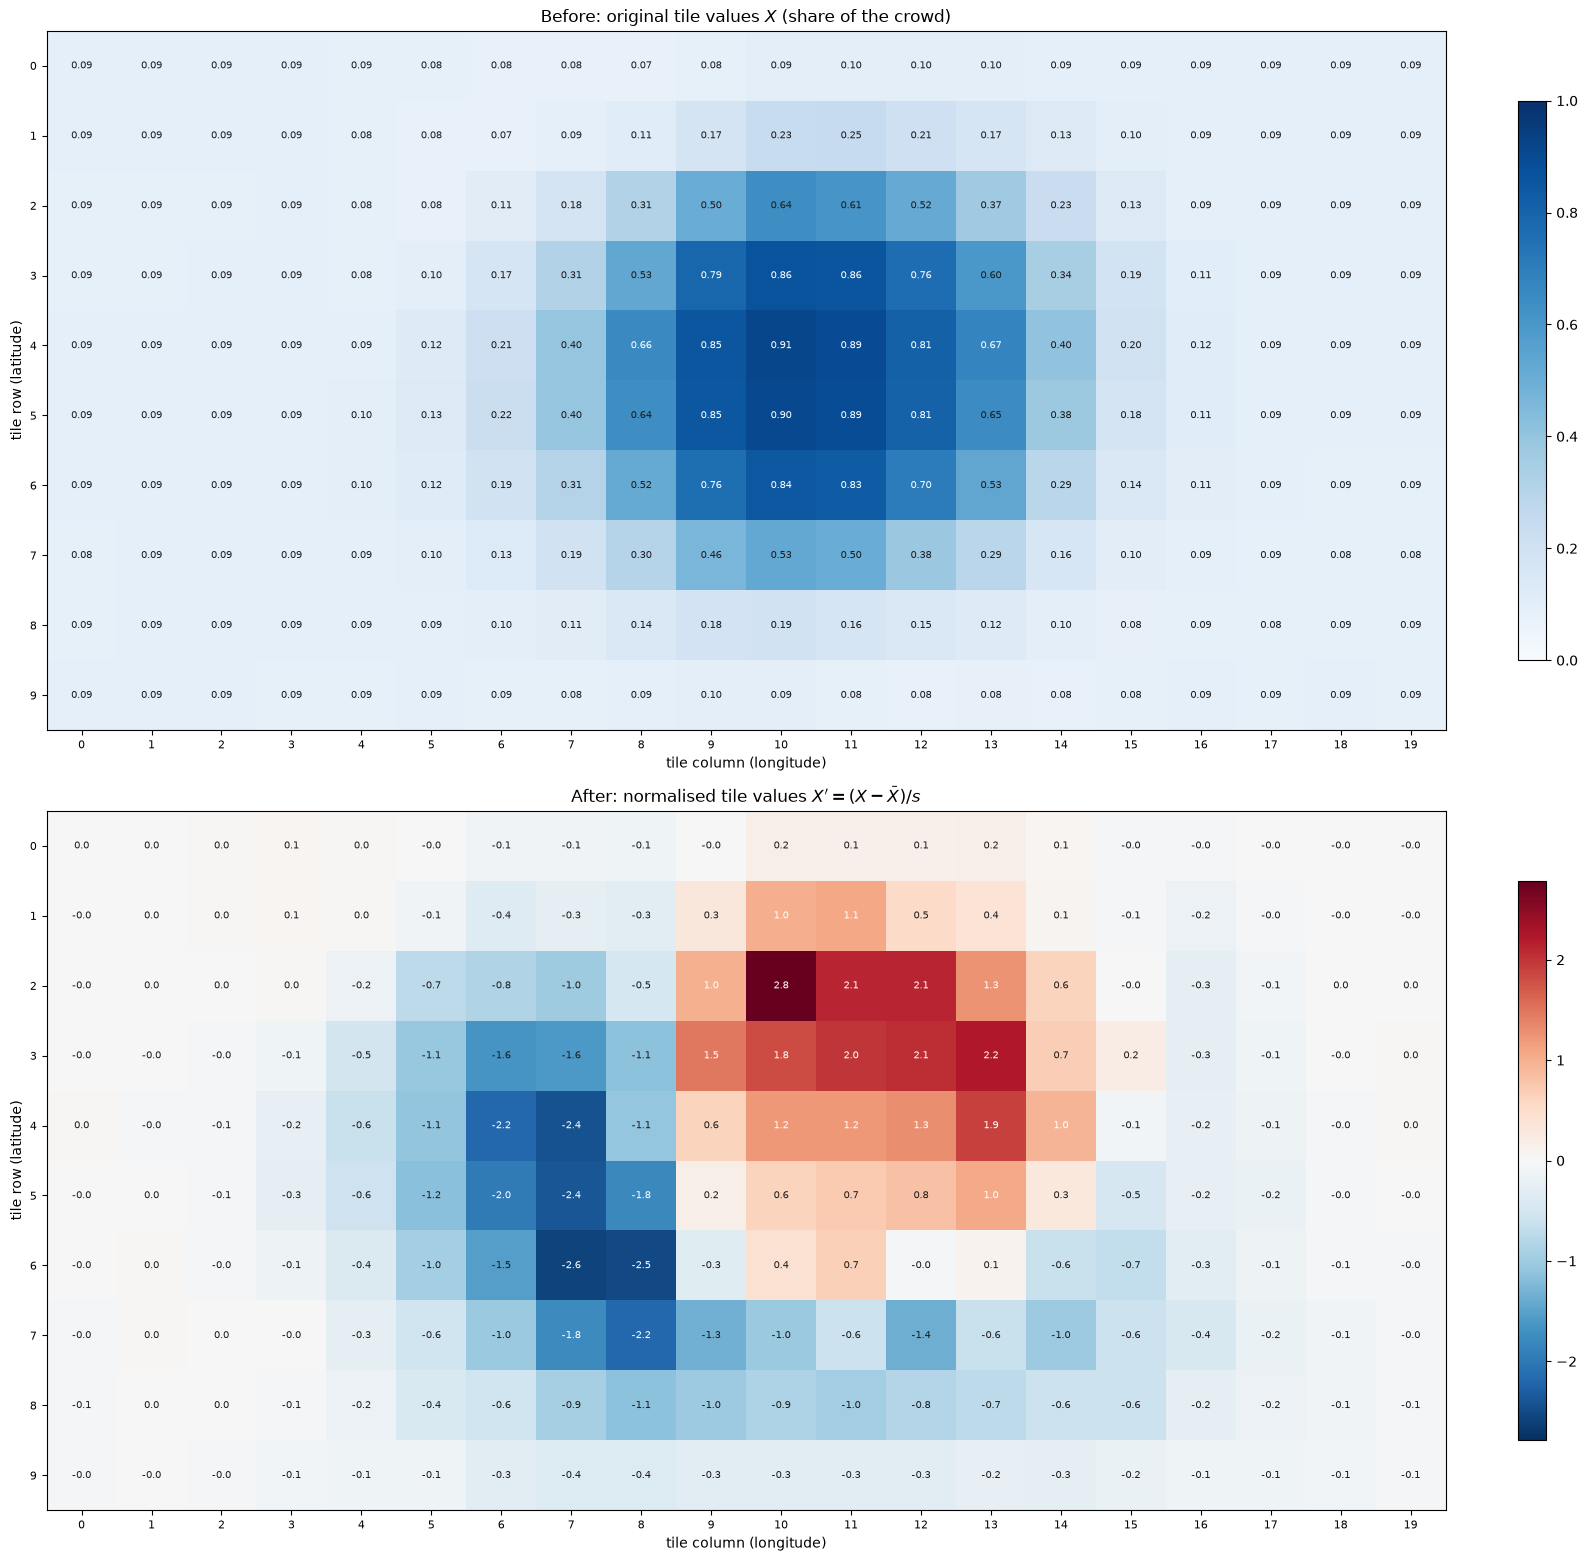

In [10]:
Xn = NORM.fwd(X0)
lim = float(np.abs(Xn).max())
fig, axes = plt.subplots(2, 1, figsize=(16, 15.5), constrained_layout=True)
for ax, m, title, cm, lo, hi, f in [
        (axes[0], X0, "Before: original tile values $X$ (share of the crowd)", "Blues", 0, 1, "{:.2f}"),
        (axes[1], Xn, "After: normalised tile values $X' = (X - \\bar X)/s$", "RdBu_r", -lim, lim, "{:.1f}")]:
    im = ax.imshow(m, cmap=cm, vmin=lo, vmax=hi, interpolation="nearest")
    for (r, c), v in np.ndenumerate(m):
        strong = (v - lo) / (hi - lo) > 0.65 or (cm == "RdBu_r" and (v - lo) / (hi - lo) < 0.2)
        ax.text(c, r, f.format(v), ha="center", va="center", fontsize=7.5, color="white" if strong else "#1d1d1f")
    ax.set_xticks(range(W)); ax.set_yticks(range(H)); ax.tick_params(labelsize=8)
    ax.set_xlabel("tile column (longitude)"); ax.set_ylabel("tile row (latitude)")
    ax.set_title(title, fontsize=12)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(os.path.join(FIG_DIR, "normalised_and_diff_weights_values.png"), dpi=130)
plt.show()

## 3. Variance per direction of the normalised frames

A latent slot is worth using along a principal direction whose variance is above $\tau_1/\tau_2$. This rule is exact
only for a linear encoder and decoder; for the nonlinear networks here it shows what to expect, and the validation
runs in section 4 check it. After normalising, the variances are $\lambda_i / s^2$, so the same ratios admit
many more directions than on the original frames.

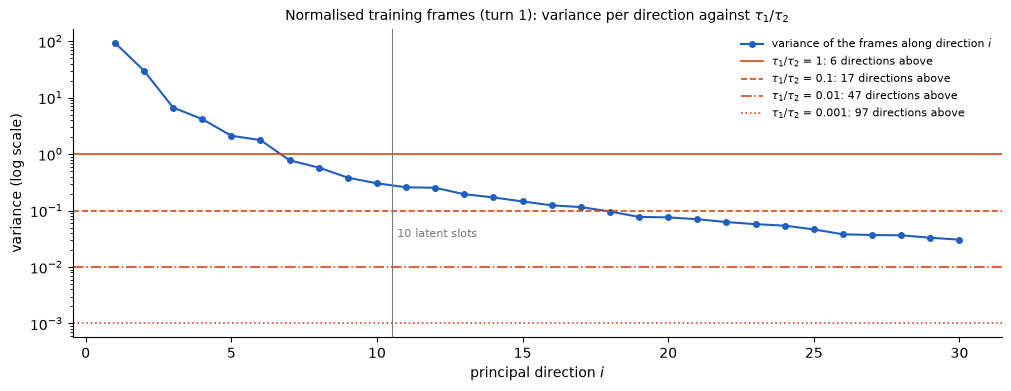

total variance of the normalised frames: 142.8   largest direction: 93.7


In [11]:
lam = eigenvalues(NORM.fwd(training_frames(PREDICTORS[(0, "val")], split(0).inner_train, np.random.default_rng())))
plot_eigenvalues(lam, [1.0, 1e-1, 1e-2, 1e-3], "Normalised training frames (turn 1): variance per direction against $\\tau_1/\\tau_2$",
                 os.path.join(FIG_DIR, "normalised_and_diff_weights_eigenvalues.png"))
print(f"total variance of the normalised frames: {lam.sum():.1f}   largest direction: {lam[0]:.1f}")

## 4. Validation results

Every setting, trained 5 times in each of the 5 turns on normalised frames and scored on the validation fold of its
turn. The table gives, per setting, the validation RMSE (mean ± standard deviation of its 25 runs, on the original tile
scale), the mean number of active latent slots, the mean KL in nats, and the error of always answering the mean frame
on the same frames.

In [12]:
TAU1 = [1 / 3, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
TAU3 = [1 / 3, 0.1, 0.01]
GRID = [(t1, 1 - t1 - t3, t3) for t3 in TAU3 for t1 in TAU1]
REPEATS = 5

tasks = [(f, "val", tau, True, rep) for f in range(5) for tau in GRID for rep in range(REPEATS)]
VAL = run_all(tasks, "normalised_and_diff_weights_validation.csv")
VAL_SUM = summarise(VAL)
print(f"{len(GRID)} settings x 5 turns x {REPEATS} repeats = {len(VAL)} validation runs")
VAL_SUM.sort_values("rmse_mean").assign(
    tau_1=lambda d: d.tau_1.map(fmt), tau_2=lambda d: d.tau_2.map(fmt), tau_3=lambda d: d.tau_3.map(fmt),
    **{"validation RMSE": lambda d: [pm(m, s) for m, s in zip(d.rmse_mean, d.rmse_std)]}
)[["tau_1", "tau_2", "tau_3", "validation RMSE", "active", "kl", "mean_frame", "runs"]].round(
    {"active": 1, "kl": 1, "mean_frame": 4}).reset_index(drop=True)

450 runs saved to results/normalised_and_diff_weights_validation.csv
18 settings x 5 turns x 5 repeats = 450 validation runs


,tau_1,tau_2,tau_3,validation RMSE,active,kl,mean_frame,runs
0,0.01,0.98,0.01,0.0131 ± 0.0025,10.0,37.4,0.0356,25
1,0.01,0.89,0.1,0.0132 ± 0.0028,10.0,37.0,0.0356,25
2,0.1,0.89,0.01,0.0132 ± 0.0028,10.0,20.1,0.0357,25
3,1e-5,0.6667,1/3,0.0132 ± 0.0028,10.0,46.8,0.0357,25
4,0.1,0.8,0.1,0.0132 ± 0.0028,10.0,19.7,0.0357,25
5,0.01,0.6567,1/3,0.0132 ± 0.0028,10.0,34.9,0.0356,25
6,1e-3,0.989,0.01,0.0132 ± 0.0027,10.0,46.5,0.0356,25
7,1e-4,0.8999,0.1,0.0133 ± 0.0032,10.0,45.4,0.0357,25
8,1e-4,0.6666,1/3,0.0133 ± 0.0024,10.0,46.7,0.0356,25
9,0.1,0.5667,1/3,0.0133 ± 0.0027,9.7,17.6,0.0356,25


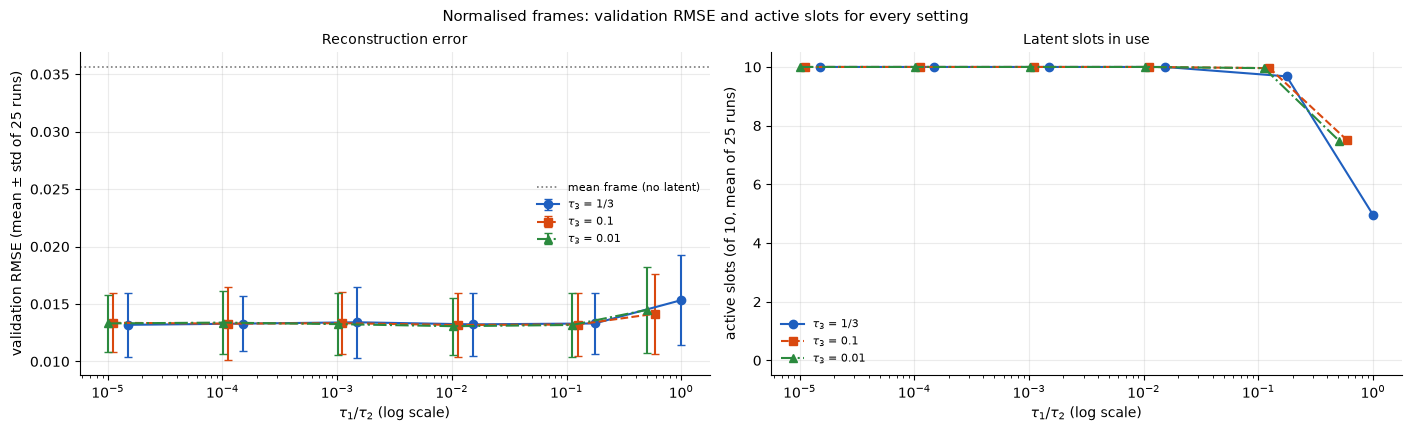

In [13]:
plot_validation(VAL_SUM, "Normalised frames: validation RMSE and active slots for every setting",
                os.path.join(FIG_DIR, "normalised_and_diff_weights_validation.png"))

## 5. Choosing the weights in each turn, and testing them

In each turn the setting with the lowest validation RMSE (averaged over its 5 repeats) is chosen. Only that setting is
trained on the 40 non-test viewers (5 more times) and scored on the test fold. The test folds play no part in the
choice. The table lists, per turn, the chosen weights, their validation RMSE and their test RMSE (mean ± standard
deviation of the 5 repeats), with the error of always answering the mean frame on the same test frames.

In [14]:
CHOICE = choose_per_fold(VAL)                    # in each turn: the lowest mean validation RMSE (decided by validation only)
tasks = [(int(r.fold) - 1, "test", (r.tau_1, r.tau_2, r.tau_3), True, rep)
         for r in CHOICE.itertuples() for rep in range(REPEATS)]
TEST = run_all(tasks, "normalised_and_diff_weights_test.csv")

per_fold = TEST.groupby("fold").agg(test_mean=("rmse", "mean"), test_std=("rmse", "std"), active=("active", "mean"),
                                    mean_frame=("mean_frame_rmse", "mean")).reset_index()
per_fold = CHOICE.rename(columns={"rmse": "validation RMSE"}).merge(per_fold, on="fold")
display_fold = per_fold.assign(**{c: per_fold[c].map(fmt) for c in ["tau_1", "tau_2", "tau_3"]},
                               **{"test RMSE": [pm(m, s) for m, s in zip(per_fold.test_mean, per_fold.test_std)]})
print(display_fold[["fold", "tau_1", "tau_2", "tau_3", "validation RMSE", "test RMSE", "active", "mean_frame"]]
      .round({"validation RMSE": 4, "active": 1, "mean_frame": 4}).to_string(index=False))
print(f"\nTEST RMSE over all 5 turns x {REPEATS} repeats: {pm(TEST.rmse.mean(), TEST.rmse.std())}   "
      f"(mean frame on the same frames: {TEST.mean_frame_rmse.mean():.4f};  active slots {TEST.active.mean():.1f} of 10)")

25 runs saved to results/normalised_and_diff_weights_test.csv
 fold tau_1  tau_2 tau_3  validation RMSE       test RMSE  active  mean_frame
    1  0.01   0.98  0.01           0.0175 0.0135 ± 0.0007    10.0      0.0367
    2  1e-4 0.8999   0.1           0.0100 0.0209 ± 0.0008    10.0      0.0351
    3   0.1    0.8   0.1           0.0116 0.0098 ± 0.0002     9.6      0.0326
    4  1e-3  0.899   0.1           0.0124 0.0115 ± 0.0004    10.0      0.0395
    5  1e-4 0.8999   0.1           0.0129 0.0112 ± 0.0005    10.0      0.0332

TEST RMSE over all 5 turns x 5 repeats: 0.0134 ± 0.0040   (mean frame on the same frames: 0.0354;  active slots 9.9 of 10)


## 6. Choosing between original and normalised frames as well

The same rule, applied to all 36 settings at once (18 weights × original or normalised frames): in each turn, the
setting with the lowest validation RMSE is chosen, and its test runs give the test RMSE of this choice. The validation
and test runs on original frames come from `pacman_vae_diff_weights.ipynb`, and the two fixed models with equal weights
from `pacman_vae_normalised_tiles.ipynb` (run both first). All of them use the same folds and the same fold predictors.

The table compares the test RMSE (mean ± standard deviation over 5 turns × 5 repeats) of every way of setting up the
model.

In [15]:
VAL_O  = pd.read_csv(os.path.join(RES_DIR, "diff_weights_validation.csv"))
TEST_O = pd.read_csv(os.path.join(RES_DIR, "diff_weights_test.csv"))
TEST_E = pd.read_csv(os.path.join(RES_DIR, "normalised_tiles_test.csv"))
KEY = ["normalised", "tau_1", "tau_2", "tau_3"]

CHOICE_ALL = choose_per_fold(pd.concat([VAL_O, VAL]), by=KEY)
TEST_ALL = pd.concat([TEST_O, TEST]).merge(CHOICE_ALL[["fold", *KEY]], on=["fold", *KEY])
assert TEST_ALL.groupby("fold").size().eq(REPEATS).all()      # the chosen setting of every turn has its 5 test runs
print("chosen in each turn (validation only):")
print(CHOICE_ALL.assign(**{c: CHOICE_ALL[c].map(fmt) for c in ["tau_1", "tau_2", "tau_3"]})
      .rename(columns={"rmse": "validation RMSE"}).round(4).to_string(index=False))

def row(name, d, tau):
    return {"how the model is set up": name, "tau": tau, "test RMSE": pm(d.rmse.mean(), d.rmse.std()),
            "active slots": round(d.active.mean(), 1), "runs": len(d)}
SUMMARY = pd.DataFrame([
    row("original frames, equal weights",               TEST_E[~TEST_E.normalised], "1/3, 1/3, 1/3"),
    row("original frames, weights chosen by validation", TEST_O, "per turn"),
    row("normalised frames, equal weights",             TEST_E[TEST_E.normalised], "1/3, 1/3, 1/3"),
    row("normalised frames, weights chosen by validation", TEST, "per turn"),
    row("frames and weights both chosen by validation",  TEST_ALL, "per turn"),
])
SUMMARY.to_csv(os.path.join(RES_DIR, "summary_test.csv"), index=False)
print(f"\nmean frame (no latent) on the same test frames: {TEST_E.mean_frame_rmse.mean():.4f}")
SUMMARY

chosen in each turn (validation only):
 fold  normalised tau_1  tau_2 tau_3  validation RMSE
    1        True  0.01   0.98  0.01           0.0175
    2        True  1e-4 0.8999   0.1           0.0100
    3        True   0.1    0.8   0.1           0.0116
    4        True  1e-3  0.899   0.1           0.0124
    5        True  1e-4 0.8999   0.1           0.0129

mean frame (no latent) on the same test frames: 0.0354


,how the model is set up,tau,test RMSE,active slots,runs
0,"original frames, equal weights","1/3, 1/3, 1/3",0.0370 ± 0.0039,0.0,25
1,"original frames, weights chosen by validation",per turn,0.0264 ± 0.0061,5.8,25
2,"normalised frames, equal weights","1/3, 1/3, 1/3",0.0157 ± 0.0066,4.9,25
3,"normalised frames, weights chosen by validation",per turn,0.0134 ± 0.0040,9.9,25
4,frames and weights both chosen by validation,per turn,0.0134 ± 0.0040,9.9,25


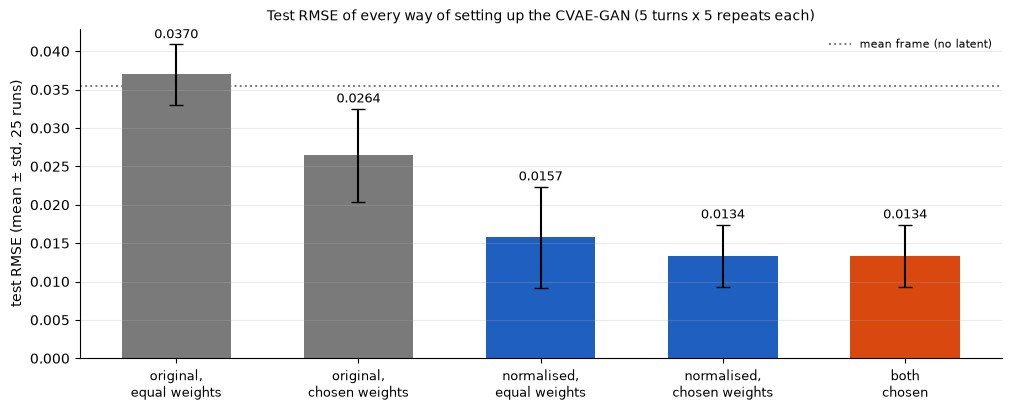

In [16]:
labels = ["original,\nequal weights", "original,\nchosen weights", "normalised,\nequal weights",
          "normalised,\nchosen weights", "both\nchosen"]
data = [TEST_E[~TEST_E.normalised], TEST_O, TEST_E[TEST_E.normalised], TEST, TEST_ALL]
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
x = np.arange(len(data))
ax.bar(x, [d.rmse.mean() for d in data], yerr=[d.rmse.std() for d in data], capsize=5,
       color=[GREY, GREY, BLUE, BLUE, ORANGE], width=0.6)
ax.axhline(TEST_E.mean_frame_rmse.mean(), color=GREY, ls=":", lw=1.4, label="mean frame (no latent)")
for i, d in enumerate(data):
    ax.text(i, d.rmse.mean() + d.rmse.std() + 0.0008, f"{d.rmse.mean():.4f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("test RMSE (mean ± std, 25 runs)")
ax.set_title("Test RMSE of every way of setting up the CVAE-GAN (5 turns x 5 repeats each)", fontsize=10)
ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.25, axis="y"); ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "normalised_and_diff_weights_comparison.png"), dpi=150)
plt.show()

## 7. The final model

The final setting is the one with the lowest validation RMSE averaged over all 25 of its runs, among all 36 settings.
It is trained on all 50 viewers, with the saved FoV predictor of `../../predictor/pacman/fov_predictor_pacman.ipynb` (`predictor_weights_pacman.pt`,
trained on all 50 viewers with Adam on binary cross-entropy), 5 times from fresh random starting weights. The saved encoder, `pacman_frozen_wt.pt`, is the one of these 5
with the lowest reconstruction error on its own training frames; no validation or test data is used for this.
Together with the normalisation statistics it holds everything needed to turn a predicted frame into the 10 numbers
$\mathrm{sigmoid}(z_k)$, each between 0 and 1.

The saved predictor's frames vary more than those of the fold predictors (section 0), so the training
error of the final encoder printed below is not directly comparable to the validation and test RMSE above.

In [17]:
ALL_SUM = summarise(pd.concat([VAL_O, VAL]), by=KEY).sort_values("rmse_mean")
FINAL = ALL_SUM.iloc[0]
final_tau, final_norm = (FINAL.tau_1, FINAL.tau_2, FINAL.tau_3), bool(FINAL.normalised)
print(f"final setting: {'normalised' if final_norm else 'original'} frames, "
      f"tau = ({fmt(final_tau[0])}, {fmt(final_tau[1])}, {fmt(final_tau[2])}), validation RMSE {pm(FINAL.rmse_mean, FINAL.rmse_std)}")

FULL_PREDICTOR = Order5Predictor(ck["base_rate"], N, cfg["width"])
FULL_PREDICTOR.load_state_dict(ck["predictor"]); FULL_PREDICTOR.eval()


def run_final(rep):
    torch.set_num_threads(1)
    seed = int.from_bytes(os.urandom(4), "little")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    train = training_frames(FULL_PREDICTOR, U, np.random.default_rng(seed))
    if final_norm:
        nm = make_normaliser(train)
        enc, dec = train_cvaegan(nm.fwd(train), final_tau, out_sigmoid=False, out_bias=0.0)
        ev = evaluate(enc, dec, nm.fwd(train).reshape(-1, H, W), nm.scale)
        stats = {"mean": nm.mean, "scale": nm.scale}
    else:
        m = float(train.mean())
        enc, dec = train_cvaegan(train, final_tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
        ev = evaluate(enc, dec, train.reshape(-1, H, W))
        stats = {"mean": None, "scale": 1.0}
    return {"repeat": rep + 1, "seed": seed, "train_rmse": ev["rmse"], "active": ev["active"],
            "encoder": enc.state_dict(), **stats}


ENCODER_FILE = "pacman_frozen_wt.pt"
if os.path.exists(ENCODER_FILE) and not RERUN:
    saved = torch.load(ENCODER_FILE, map_location=DEVICE, weights_only=False)
    print(f"loaded {ENCODER_FILE}: repeat {saved['repeat']} of 5, training RMSE {saved['train_rmse']:.4f}, "
          f"{saved['active']} active slots  (set RERUN = True to train it again)")
else:
    finals = Parallel(n_jobs=N_WORKERS)(delayed(run_final)(rep) for rep in range(5))
    print(pd.DataFrame([{k: v for k, v in r.items() if k in ("repeat", "seed", "train_rmse", "active")} for r in finals])
          .round(4).to_string(index=False))
    best = min(finals, key=lambda r: r["train_rmse"])
    torch.save({"encoder": best["encoder"], "L": 10, "hidden": [128, 64], "leak": 0.2, "input_shape": (H, W),
                "tau": list(final_tau), "normalised": final_norm, "latent_sigmoid": True, "norm_mean": best["mean"], "norm_scale": best["scale"],
                "repeat": best["repeat"], "seed": best["seed"], "train_rmse": best["train_rmse"], "active": best["active"]},
               ENCODER_FILE)
    print(f"\nsaved {ENCODER_FILE}: repeat {best['repeat']} (lowest training RMSE {best['train_rmse']:.4f}, "
          f"{best['active']} active slots)")

final setting: normalised frames, tau = (0.01, 0.98, 0.01), validation RMSE 0.0131 ± 0.0025


 repeat       seed  train_rmse  active
      1 2291058200      0.0182      10
      2 1619382422      0.0180      10
      3 2215032886      0.0184      10
      4 3061767415      0.0184      10
      5 1879947208      0.0171      10

saved pacman_frozen_wt.pt: repeat 5 (lowest training RMSE 0.0171, 10 active slots)


## 8. One example run

One more training of the final setting in turn 1 (on the 40 non-test viewers): the 7 test frames of turn 1, their
reconstruction from one drawn $z_k$, and the spread $\sigma_{z,k}$ of each latent slot.

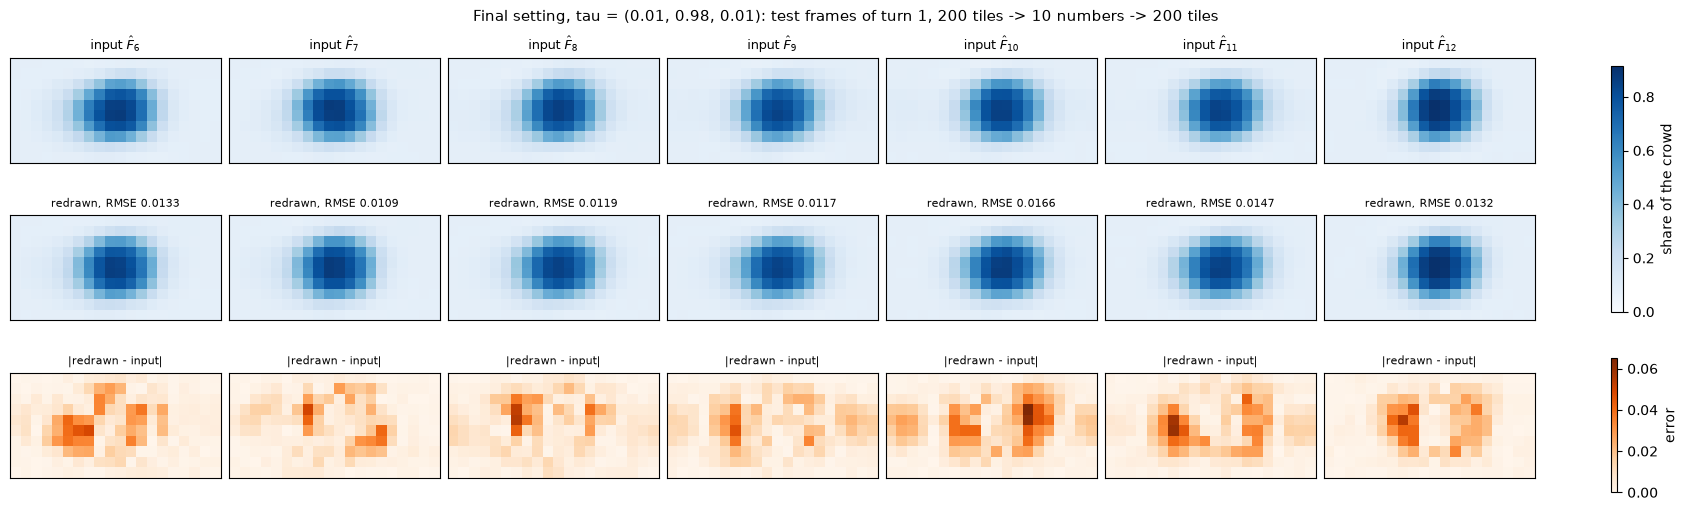

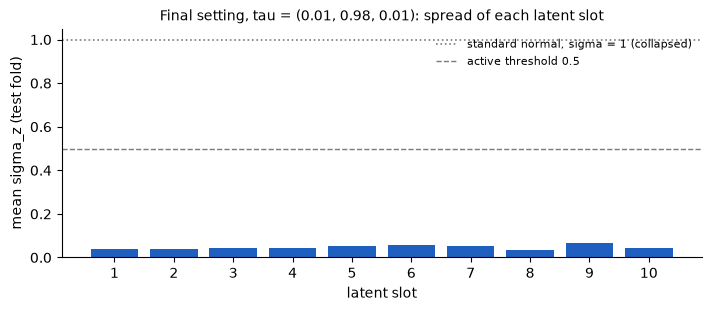

In [18]:
A, R, sigma = example_run(0, final_tau, final_norm)
name = f"tau = ({fmt(final_tau[0])}, {fmt(final_tau[1])}, {fmt(final_tau[2])})"
plot_reconstruction(A, R, f"Final setting, {name}: test frames of turn 1, 200 tiles -> 10 numbers -> 200 tiles",
                    os.path.join(FIG_DIR, "normalised_and_diff_weights_example_reconstruction.png"))
plot_slots(sigma, f"Final setting, {name}: spread of each latent slot",
           os.path.join(FIG_DIR, "normalised_and_diff_weights_example_slots.png"))

## 9. What the results show

The validation RMSE of every setting is in the table of section 4, and the test RMSE of every way of setting up the
model in section 6. The cell below summarises them per value of $\tau_1$ on normalised frames. What to look for:

- **whether every setting on normalised frames is far below the mean frame**;
- **how the weights decide the number of slots in use**, and whether lowering $\tau_1$ further still helps (the KL
  rises; the sigmoid in front of the decoder squashes values of $z_k$ far from 0 to almost 0 or 1, so extra precision
  in $z_k$ can hardly be used);
- **how large the differences between the best settings are**, compared with the differences between runs, and
  whether on the test folds weights chosen by validation beat equal weights in every turn;
- **whether choosing the input scale as well picks normalised frames in every turn** (section 6).

### Conclusion

The final setting by the rule fixed before the runs (lowest validation RMSE over all 36 settings, 25 runs each),
which is the one saved in `pacman_frozen_wt.pt`, is printed below with its test result.

In [19]:
by_t1 = VAL_SUM.groupby("tau_1").agg(rmse_lo=("rmse_mean", "min"), rmse_hi=("rmse_mean", "max"),
                                     active_lo=("active", "min"), active_hi=("active", "max"),
                                     kl=("kl", "mean")).sort_index(ascending=False)
print(f"normalised frames, validation; mean frame (no latent): {VAL_SUM.mean_frame.mean():.4f}")
print(by_t1.rename(index=fmt).round({"rmse_lo": 4, "rmse_hi": 4, "active_lo": 1, "active_hi": 1, "kl": 1}).to_string())

EQ_N = TEST_E[TEST_E.normalised]
d = EQ_N.groupby("fold").rmse.mean() - TEST.groupby("fold").rmse.mean()
print(f"\ntest folds: weights chosen by validation {pm(TEST.rmse.mean(), TEST.rmse.std())}  vs  equal weights "
      f"{pm(EQ_N.rmse.mean(), EQ_N.rmse.std())}: better in {(d > 0).sum()} of 5 turns ({d.min():+.4f} to {d.max():+.4f})")
print(f"choosing the input scale as well picks normalised frames in {int(CHOICE_ALL.normalised.sum())} of 5 turns")

near = ALL_SUM[ALL_SUM.rmse_mean <= FINAL.rmse_mean + 1e-4]
mf = TEST_E.mean_frame_rmse.mean()
eq_o = TEST_E[~TEST_E.normalised]
print("\n" + "=" * 100)
print(f"FINAL SETTING for video '{cfg['folder']}': {'normalised' if final_norm else 'original'} frames,")
print(f"    tau_1 = {fmt(final_tau[0])},  tau_2 = {fmt(final_tau[1])},  tau_3 = {fmt(final_tau[2])},  "
      f"validation RMSE = {pm(FINAL.rmse_mean, FINAL.rmse_std)},  {FINAL.active:.1f} of 10 slots in use")
print(f"test RMSE, input scale and weights chosen per turn: {pm(TEST_ALL.rmse.mean(), TEST_ALL.rmse.std())}  "
      f"({mf / TEST_ALL.rmse.mean():.1f} x below the mean frame {mf:.4f}; "
      f"equal weights on original frames {pm(eq_o.rmse.mean(), eq_o.rmse.std())})")
print(f"settings within 0.0001 of the final one on validation: {len(near)}")
print("=" * 100)

normalised frames, validation; mean frame (no latent): 0.0356
       rmse_lo  rmse_hi  active_lo  active_hi    kl
tau_1                                              
1/3     0.0141   0.0153        5.0        7.5   9.6
0.1     0.0132   0.0133        9.7       10.0  19.1
0.01    0.0131   0.0132       10.0       10.0  36.4
1e-3    0.0132   0.0134       10.0       10.0  46.4
1e-4    0.0133   0.0134       10.0       10.0  46.0
1e-5    0.0132   0.0134       10.0       10.0  47.2

test folds: weights chosen by validation 0.0134 ± 0.0040  vs  equal weights 0.0157 ± 0.0066: better in 5 of 5 turns (+0.0002 to +0.0075)
choosing the input scale as well picks normalised frames in 5 of 5 turns

FINAL SETTING for video 'pacman': normalised frames,
    tau_1 = 0.01,  tau_2 = 0.98,  tau_3 = 0.01,  validation RMSE = 0.0131 ± 0.0025,  10.0 of 10 slots in use
test RMSE, input scale and weights chosen per turn: 0.0134 ± 0.0040  (2.6 x below the mean frame 0.0354; equal weights on original frames 0.0370 ± 0